In [5]:
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] ='Malgun Gothic'
plt.rcParams['axes.unicode_minus'] =False

# 1) 데이터 수집 : F201
# CSV 파일 읽어오기
csv = pd.read_csv('NFLX.csv') 
df = pd.DataFrame(csv)

In [7]:
# 2) 데이터 전처리: F202
new_df = df.loc[:, 'Date':'Close']

# DataFrame 출력
print(new_df)

            Date        Open        High         Low       Close
0     2018-02-05  262.000000  267.899994  250.029999  254.259995
1     2018-02-06  247.699997  266.700012  245.000000  265.720001
2     2018-02-07  266.579987  272.450012  264.329987  264.559998
3     2018-02-08  267.079987  267.619995  250.000000  250.100006
4     2018-02-09  253.850006  255.800003  236.110001  249.470001
...          ...         ...         ...         ...         ...
1004  2022-01-31  401.970001  427.700012  398.200012  427.140015
1005  2022-02-01  432.959991  458.480011  425.540009  457.130005
1006  2022-02-02  448.250000  451.980011  426.480011  429.480011
1007  2022-02-03  421.440002  429.260010  404.279999  405.600006
1008  2022-02-04  407.309998  412.769989  396.640015  410.170013

[1009 rows x 5 columns]


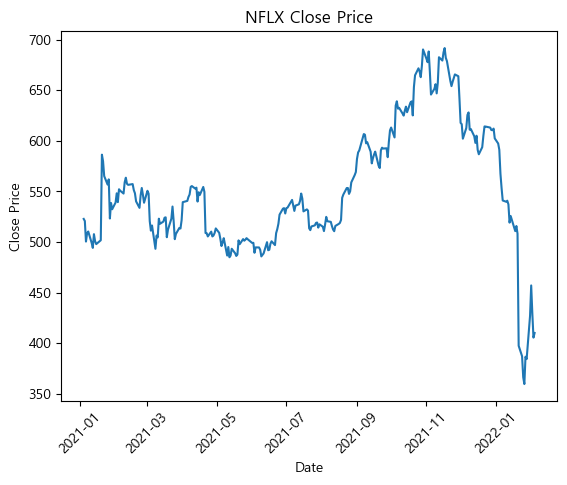

In [8]:
# 3) 2021년 이후의 데이터 필터링: F203
# 2021년 이후 데이터 필터링
df_after_2021 = new_df[new_df["Date"] >= "2021-01-01"]

# 날짜 데이터 변환
new_df["Date"] = pd.to_datetime(df_after_2021["Date"])

# 그래프 그리기 (가로, 세로 축에 표시될 데이터를 차례로 기입)
plt.plot(new_df['Date'], new_df['Close'])

# 그래프 제목 설정
plt.title('NFLX Close Price')

# x축 레이블 설정
plt.xlabel('Date')

# y축 레이블 설정
plt.ylabel('Close Price')

# x 축 설정(회전시키기)
plt.xticks(rotation=45)

# 그래프 표시
plt.show()

In [9]:
# 4) 최고/최저 종가 추출: F204
# 최고가, 최저가 구하기
max_price = df_after_2021['Close'].max()
min_price = df_after_2021['Close'].min()

print("최고 종가:", max_price)
print("최저 종가:", min_price)

최고 종가: 691.690002
최저 종가: 359.700012


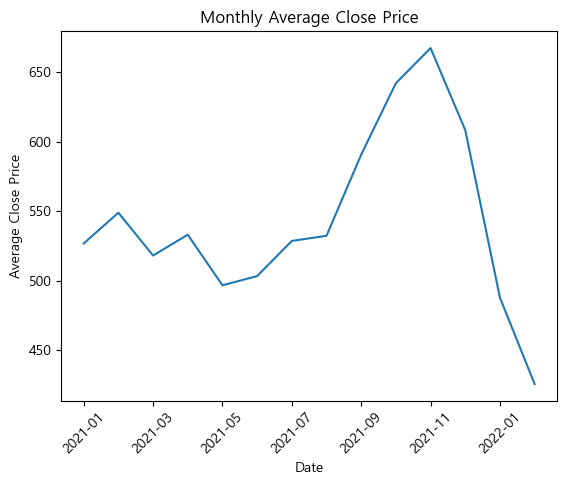

In [10]:
# 5) 월별 평균 종가 계산: F205
# 월별 평균 종가 계산
df_after_2021['Month'] = pd.to_datetime(df_after_2021['Date']).dt.to_period('M')
monthly_df = df_after_2021.groupby('Month', as_index=False)['Close'].mean()

# Period 타입을 문자열로 미리 바꿔두기 (그래프 깨짐 방지)
monthly_df['Month'] = monthly_df['Month'].astype(str)

# 그래프 그리기 (가로, 세로 축에 표시될 데이터를 차례로 기입)
plt.plot(monthly_df['Month'], monthly_df['Close'])

# 그래프 제목 설정
plt.title('Monthly Average Close Price')

# x축 레이블 설정
plt.xlabel('Date')

# y축 레이블 설정
plt.ylabel('Average Close Price')

# x 축 설정(2달 간격으로 나타내기 및 회전시키기)
plt.xticks(ticks=monthly_df['Month'][::2], labels=monthly_df['Month'][::2], rotation=45)

# 그래프 표시
plt.show()

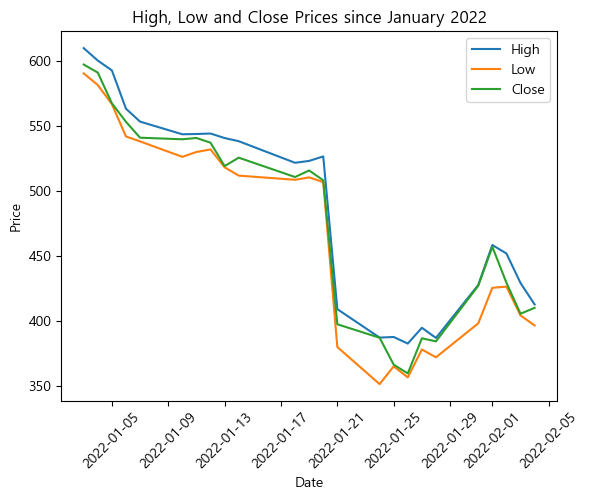

In [11]:
# 6) 2022년 이후의 최고가, 최저가, 종가 시각화: F206
# 2022년 이후 데이터 필터링
df_after_2022 = new_df[new_df["Date"] >= "2022-01-01"]

# 그래프 그리기
plt.plot(df_after_2022['Date'], df_after_2022['High'], label='High')
plt.plot(df_after_2022['Date'], df_after_2022['Low'], label='Low')
plt.plot(df_after_2022['Date'], df_after_2022['Close'], label='Close')
# 그래프 제목 설정
plt.title('High, Low and Close Prices since January 2022')

# x축 레이블 설정
plt.xlabel('Date')

# y축 레이블 설정
plt.ylabel('Price')

# x 축 설정(회전시키기)
plt.xticks(rotation=45)

# 범례 표시
plt.legend()

# 그래프 표시
plt.show()